In [3]:
import os
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler

warnings.filterwarnings('ignore')

# Root folder based on your desktop workspace
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = PROJECT_ROOT / "data"
REPORT_DIR = PROJECT_ROOT / "reports"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

# Create directories if they do not exist
for directory in [DATA_DIR, REPORT_DIR, MODEL_DIR, RESULTS_DIR]:
    os.makedirs(directory, exist_ok=True)

# Dataset file path
DATASET_PATH = PROJECT_ROOT / "data" / "raw" / "banking_loan_approval_dataset_100k.csv"

TARGET_COL = 'LOAN_APPROVAL'

# Continuous features targeted for fuzzy membership transformation
FUZZY_INPUT_COLS = ['age', 'balance', 'duration']

# Training & evaluation parameters
RANDOM_STATE = 42
TEST_SIZE = 0.20
DECISION_THRESHOLD = 0.75

print("Setup completed successfully. Directories and model inputs initialized.")

Setup completed successfully. Directories and model inputs initialized.


In [4]:
df = pd.read_csv(DATASET_PATH)

categorical_cols = df.select_dtypes(exclude=['number', 'bool']).columns
le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

In [5]:
def fuzzy_membership(x, a, b, c):
    return np.maximum(0, np.minimum((x - a) / (b - a + 1e-9), (c - x) / (c - b + 1e-9)))

df['age_young'] = fuzzy_membership(df['age'], 18, 25, 40)
df['age_middle'] = fuzzy_membership(df['age'], 30, 45, 60)
df['age_senior'] = fuzzy_membership(df['age'], 50, 75, 100)

df['bal_low'] = fuzzy_membership(df['balance'], -2000, 0, 50000)
df['bal_med'] = fuzzy_membership(df['balance'], 20000, 75000, 120000)
df['bal_high'] = fuzzy_membership(df['balance'], 80000, 150000, 200000)

df['dur_short'] = fuzzy_membership(df['duration'], 0, 0, 800)
df['dur_med'] = fuzzy_membership(df['duration'], 400, 1000, 1600)
df['dur_long'] = fuzzy_membership(df['duration'], 1200, 2000, 3000)

X = df.drop(columns=[TARGET_COL] + FUZZY_INPUT_COLS)
y = df[TARGET_COL]

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

ann_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    max_iter=200,
    random_state=RANDOM_STATE
)
ann_model.fit(X_train, y_train)

y_prob = ann_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= DECISION_THRESHOLD).astype(int)

print(f"\n--- Neuro-Fuzzy Evaluation at {DECISION_THRESHOLD*100}% Threshold ---")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


--- Neuro-Fuzzy Evaluation at 75.0% Threshold ---

Confusion Matrix:
[[3913 1499]
 [5987 8601]]

Classification Report:
              precision    recall  f1-score   support

           0       0.40      0.72      0.51      5412
           1       0.85      0.59      0.70     14588

    accuracy                           0.63     20000
   macro avg       0.62      0.66      0.60     20000
weighted avg       0.73      0.63      0.65     20000



In [7]:
import pandas as pd
from pathlib import Path

def load_split(split_name: str, data_dir: Path = None, target_col: str = 'LOAN_APPROVAL') -> pd.DataFrame:
    if data_dir is None:
        # Defaults to a processed directory inside DATA_DIR
        data_dir = DATA_DIR / "processed" if 'DATA_DIR' in globals() else Path("data/processed")
        
    file_path = data_dir / f"{split_name}.csv"
    
    # 1. Existence check
    if not file_path.is_file():
        raise FileNotFoundError(f"[Validation Error] Expected data file not found at: {file_path}")
        
    # 2. Load dataset
    df = pd.read_csv(file_path)
    
    # 3. Check for empty dataframe
    if df.empty:
        raise ValueError(f"[Validation Error] Split file '{file_path.name}' is empty.")
        
    # 4. Check target column existence (if applicable)
    if target_col and target_col not in df.columns:
        raise KeyError(f"[Validation Error] Expected target column '{target_col}' not found in '{file_path.name}'.")
        
    # 5. Check for null/missing values
    missing_count = df.isnull().sum().sum()
    if missing_count > 0:
        raise ValueError(
            f"[Validation Error] Split '{file_path.name}' contains {missing_count} missing value(s). "
            f"All splits must have zero missing values before modeling."
        )
        
    print(f"Successfully loaded '{file_path.name}': {df.shape[0]} rows, {df.shape[1]} columns (0 missing values).")
    return df

In [8]:
# 1. Load all three splits using the Action 14 load_split function
train_df = load_split('train')
val_df = load_split('validation')
test_df = load_split('test')

# 2. Check and display row counts and shapes
print("\n" + "="*50)
print("SPLIT SIZES & ROW COUNTS")
print("="*50)
print(f"Training split rows:   {len(train_df):>7} (Shape: {train_df.shape})")
print(f"Validation split rows: {len(val_df):>7} (Shape: {val_df.shape})")
print(f"Test split rows:       {len(test_df):>7} (Shape: {test_df.shape})")

# Verify training is the largest split
assert len(train_df) > len(val_df) and len(train_df) > len(test_df), (
    "Training set should have more samples than validation or test sets."
)

# 3. Check and display class proportions for each split
print("\n" + "="*50)
print(f"CLASS PROPORTIONS ({TARGET_COL})")
print("="*50)

for name, df_split in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    proportions = df_split[TARGET_COL].value_counts(normalize=True).to_dict()
    formatted = ", ".join([f"Class {cls}: {pct:.2%}" for cls, pct in proportions.items()])
    print(f"{name:<12} -> {formatted}")

# 4. Display preview of the training data
print("\n" + "="*50)
print("TRAINING DATA PREVIEW (First 5 Rows)")
print("="*50)
display(train_df.head())

Successfully loaded 'train.csv': 69999 rows, 17 columns (0 missing values).
Successfully loaded 'validation.csv': 14999 rows, 17 columns (0 missing values).
Successfully loaded 'test.csv': 15002 rows, 17 columns (0 missing values).

SPLIT SIZES & ROW COUNTS
Training split rows:     69999 (Shape: (69999, 17))
Validation split rows:   14999 (Shape: (14999, 17))
Test split rows:         15002 (Shape: (15002, 17))

CLASS PROPORTIONS (LOAN_APPROVAL)
Train        -> Class 1: 72.94%, Class 0: 27.06%
Validation   -> Class 1: 72.94%, Class 0: 27.06%
Test         -> Class 1: 72.94%, Class 0: 27.06%

TRAINING DATA PREVIEW (First 5 Rows)


,age,job,marital,education,default,balance,housing_loan,personal_loan,contact,day,month,duration,campaign,pdays,previous,poutcome,LOAN_APPROVAL
0,64,services,married,primary,0,67149,0,1,telephone,16,jan,1045,5,64,6,success,0
1,62,retired,married,secondary,0,58771,1,1,cellular,15,sep,1342,12,383,8,failure,1
2,53,services,divorced,primary,0,36231,0,1,cellular,12,sep,416,7,48,2,failure,1
3,48,management,single,tertiary,0,53821,0,0,telephone,22,mar,757,9,225,1,success,1
4,22,retired,single,primary,0,82648,0,1,telephone,13,oct,417,13,263,4,unknown,0


In [9]:
# 1. Separate training features (X) and target (y)
X_train = train_df.drop(columns=[TARGET_COL])
y_train = train_df[TARGET_COL]

# 2. Do the same for validation and test splits
X_val = val_df.drop(columns=[TARGET_COL])
y_val = val_df[TARGET_COL]

X_test = test_df.drop(columns=[TARGET_COL])
y_test = test_df[TARGET_COL]

# 3. Print shapes to confirm separation
print(f"X_train shape: {X_train.shape}  |  y_train shape: {y_train.shape}")
print(f"X_val shape:   {X_val.shape}  |  y_val shape:   {y_val.shape}")
print(f"X_test shape:  {X_test.shape}  |  y_test shape:  {y_test.shape}")

X_train shape: (69999, 16)  |  y_train shape: (69999,)
X_val shape:   (14999, 16)  |  y_val shape:   (14999,)
X_test shape:  (15002, 16)  |  y_test shape:  (15002,)


In [10]:
import sklearn
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.neural_network import MLPClassifier

# Enable interactive visual pipeline display
sklearn.set_config(display="diagram")

# 1. Identify numeric vs categorical columns automatically from X_train
numeric_features = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=['number']).columns.tolist()

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

# 2. Build preprocessor: scale numbers, encode text strings (like 'services')
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features)
    ]
)

# 3. Create full pipeline
ann_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('ann', MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation='relu',
        solver='adam',
        max_iter=200,
        random_state=42
    ))
])

# 4. Print architecture summary and display visual pipeline
total_features = len(numeric_features) + len(categorical_features)
print(f"\nANN architecture: {total_features} inputs -> 32 hidden -> 16 hidden -> 1 output")
display(ann_pipeline)

Numeric features (10): ['age', 'default', 'balance', 'housing_loan', 'personal_loan', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical features (6): ['job', 'marital', 'education', 'contact', 'month', 'poutcome']

ANN architecture: 16 inputs -> 32 hidden -> 16 hidden -> 1 output


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('ann', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the o

In [11]:
categorical_cols = df.select_dtypes(exclude=['number', 'bool']).columns
le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])


from sklearn.preprocessing import OrdinalEncoder

# Identify all categorical (string/text) columns in the training split
categorical_cols = train_df.select_dtypes(exclude=['number', 'bool']).columns.tolist()

if categorical_cols:
    print(f"Encoding categorical columns: {categorical_cols}")
    
    # Fit encoder only on training data to prevent data leakage, then transform all splits
    encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    
    train_df[categorical_cols] = encoder.fit_transform(train_df[categorical_cols])
    val_df[categorical_cols] = encoder.transform(val_df[categorical_cols])
    test_df[categorical_cols] = encoder.transform(test_df[categorical_cols])
    print("Categorical encoding complete.")
else:
    print("No categorical string columns found.")

Encoding categorical columns: ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
Categorical encoding complete.


In [12]:
print("Training the Artificial Neural Network pipeline...")

# 1. Fit the pipeline on training features and labels
ann_pipeline.fit(X_train, y_train)

# 2. Extract the trained MLPClassifier from the pipeline
trained_ann = ann_pipeline.named_steps['ann']

# 3. Retrieve and print iterations and loss
num_iterations = trained_ann.n_iter_
final_loss = trained_ann.loss_

print("\n" + "="*45)
print("ANN TRAINING COMPLETE")
print("="*45)
print(f"Iterations completed: {num_iterations}")
print(f"Final training loss:   {final_loss:.5f}")

Training the Artificial Neural Network pipeline...

ANN TRAINING COMPLETE
Iterations completed: 137
Final training loss:   0.50087


In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

def metric_row(model, X, y_true, split_name: str, threshold: float = None) -> pd.DataFrame:
    """
    Computes Accuracy, Precision, Recall, and F1-score for a given split
    and returns the result as a single-row DataFrame.
    """
    # 1. Generate predictions (either by decision threshold or default .predict)
    if threshold is not None and hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X)[:, 1]
        y_pred = (y_prob >= threshold).astype(int)
    else:
        y_pred = model.predict(X)
        
    # 2. Calculate core classification metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    # 3. Format as a clean comparison table row
    metrics_df = pd.DataFrame([{
        'Split': split_name,
        'Threshold': f"{threshold:.2f}" if threshold is not None else "0.50 (default)",
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    }])
    
    return metrics_df

# ------------------------------------------------------------------------------
# Evaluate on Validation Data
# ------------------------------------------------------------------------------
# Default decision threshold (0.50)
val_metrics_default = metric_row(ann_pipeline, X_val, y_val, split_name="Validation (Default)")

# Strict project threshold (0.75 for loan approval)
val_metrics_strict = metric_row(ann_pipeline, X_val, y_val, split_name="Validation (Strict 0.75)", threshold=0.75)

# Combine and display the metric table
validation_summary = pd.concat([val_metrics_default, val_metrics_strict], ignore_index=True)

print("Validation Split Performance:")
display(validation_summary)

Validation Split Performance:


,Split,Threshold,Accuracy,Precision,Recall,F1-Score
0,Validation (Default),0.50 (default),0.7493,0.7710,0.9336,0.8446
1,Validation (Strict 0.75),0.75,0.6558,0.8516,0.6395,0.7305


In [14]:
# Save validation results to the results folder for viva/documentation
results_path = RESULTS_DIR / "validation_metrics.csv"
validation_summary.to_csv(results_path, index=False)
print(f"Validation metrics recorded and saved to: {results_path}")

Validation metrics recorded and saved to: c:\Users\ayush\OneDrive\Desktop\Project26-27\AHPV_Credit_Risk_Detection_Model\results\validation_metrics.csv


Loss curve successfully saved to: c:\Users\ayush\OneDrive\Desktop\Project26-27\AHPV_Credit_Risk_Detection_Model\results\step3_ann_loss_curve.png


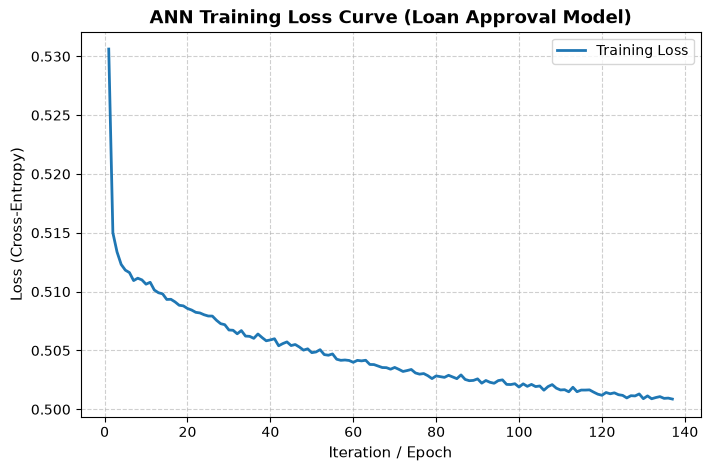

In [15]:
import matplotlib.pyplot as plt

# 1. Retrieve the loss curve from the trained MLPClassifier inside the pipeline
loss_history = ann_pipeline.named_steps['ann'].loss_curve_

# 2. Plot loss against iteration number
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(loss_history) + 1), loss_history, color='#1f77b4', linewidth=2, label='Training Loss')

plt.title('ANN Training Loss Curve (Loan Approval Model)', fontsize=13, fontweight='bold')
plt.xlabel('Iteration / Epoch', fontsize=11)
plt.ylabel('Loss (Cross-Entropy)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')

# 3. Save the figure to the specified results directory
loss_curve_path = RESULTS_DIR / "step3_ann_loss_curve.png"
plt.savefig(loss_curve_path, dpi=300, bbox_inches='tight')
print(f"Loss curve successfully saved to: {loss_curve_path}")

# 4. Display the plot in the notebook
plt.show()

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def show_confusion_matrix(y_true, y_pred, title: str = "Confusion Matrix", 
                          class_names=None, save_filename: str = None):
    """
    Plots a labeled confusion matrix with actual values on rows
    and predicted values on columns.
    """
    if class_names is None:
        class_names = ['Rejected (0)', 'Approved (1)']
        
    # 1. Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # 2. Plot heatmap
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='d', 
        cmap='Blues', 
        cbar=False,
        xticklabels=class_names, 
        yticklabels=class_names
    )
    
    plt.title(title, fontsize=12, fontweight='bold', pad=12)
    plt.xlabel('Predicted Value', fontsize=11, labelpad=10)
    plt.ylabel('Actual Value', fontsize=11, labelpad=10)
    
    # 3. Save figure if a filename is provided
    if save_filename and 'RESULTS_DIR' in globals():
        save_path = RESULTS_DIR / save_filename
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Matrix saved to: {save_path}")
        
    plt.tight_layout()
    plt.show()

Matrix saved to: c:\Users\ayush\OneDrive\Desktop\Project26-27\AHPV_Credit_Risk_Detection_Model\results\validation_confusion_matrix.png


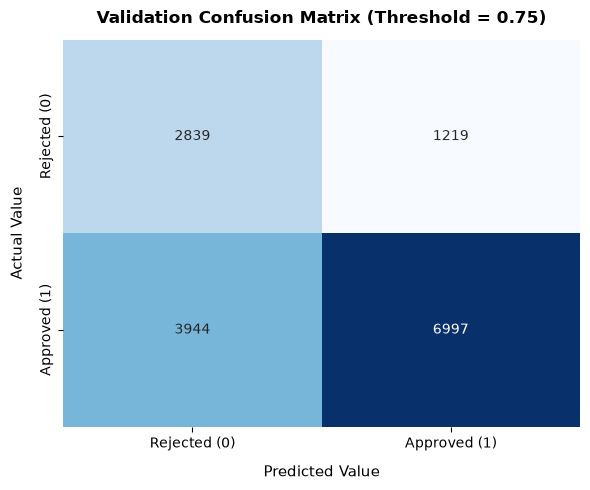

In [17]:
show_confusion_matrix(y_val, 
    (ann_pipeline.predict_proba(X_val)[:, 1] >= 0.75).astype(int), 
    title="Validation Confusion Matrix (Threshold = 0.75)", 
    save_filename="validation_confusion_matrix.png"
)

FINAL MODEL EVALUATION SUMMARY TABLE


,Split,Threshold,Accuracy,Precision,Recall,F1-Score
0,Validation,0.50 (default),0.7493,0.7710,0.9336,0.8446
1,Test,0.50 (default),0.7489,0.7715,0.9316,0.8440


Summary table saved to: c:\Users\ayush\OneDrive\Desktop\Project26-27\AHPV_Credit_Risk_Detection_Model\results\final_model_evaluation_summary.csv

FINAL TEST CLASSIFICATION REPORT (Per-Class Performance)
                    precision    recall  f1-score   support

Rejected (Class 0)       0.58      0.26      0.36      4060
Approved (Class 1)       0.77      0.93      0.84     10942

          accuracy                           0.75     15002
         macro avg       0.68      0.59      0.60     15002
      weighted avg       0.72      0.75      0.71     15002

Matrix saved to: c:\Users\ayush\OneDrive\Desktop\Project26-27\AHPV_Credit_Risk_Detection_Model\results\step3_test_confusion_matrix.png


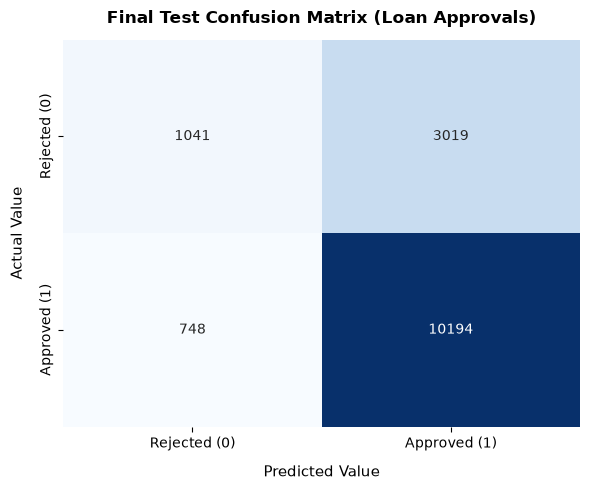

In [18]:
from sklearn.metrics import classification_report
import pandas as pd

# 1. Compute metric rows for both Validation and Test splits using metric_row from Action 20
val_row = metric_row(ann_pipeline, X_val, y_val, split_name="Validation")
test_row = metric_row(ann_pipeline, X_test, y_test, split_name="Test")

# 2. Combine into a unified summary table showing both validation and test
final_comparison_df = pd.concat([val_row, test_row], ignore_index=True)

print("="*60)
print("FINAL MODEL EVALUATION SUMMARY TABLE")
print("="*60)
display(final_comparison_df)

# Save summary table to results directory
summary_path = RESULTS_DIR / "final_model_evaluation_summary.csv"
final_comparison_df.to_csv(summary_path, index=False)
print(f"Summary table saved to: {summary_path}\n")

# 3. Generate test predictions and detailed per-class classification report
y_test_pred = ann_pipeline.predict(X_test)

target_names = ['Rejected (Class 0)', 'Approved (Class 1)']
print("="*60)
print("FINAL TEST CLASSIFICATION REPORT (Per-Class Performance)")
print("="*60)
print(classification_report(y_test, y_test_pred, target_names=target_names))

# 4. Display and save the Test Confusion Matrix using the Action 23 function
show_confusion_matrix(
    y_true=y_test,
    y_pred=y_test_pred,
    title="Final Test Confusion Matrix (Loan Approvals)",
    class_names=['Rejected (0)', 'Approved (1)'],
    save_filename="step3_test_confusion_matrix.png"
)

Combined matrices saved to: c:\Users\ayush\OneDrive\Desktop\Project26-27\AHPV_Credit_Risk_Detection_Model\results\step3_val_test_confusion_matrices.png


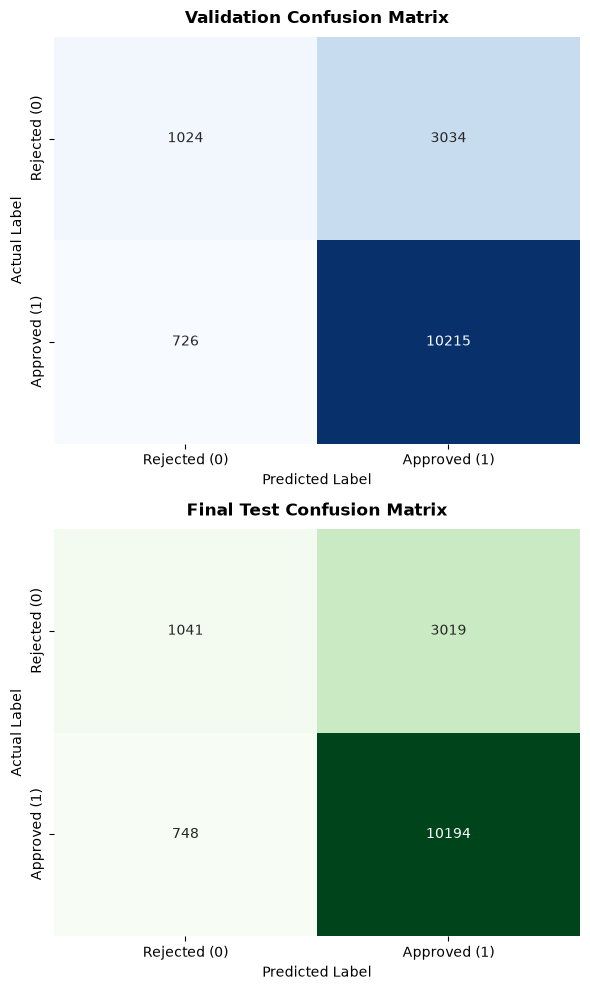

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Compute predictions for both splits
y_val_pred = ann_pipeline.predict(X_val)
y_test_pred = ann_pipeline.predict(X_test)

cm_val = confusion_matrix(y_val, y_val_pred)
cm_test = confusion_matrix(y_test, y_test_pred)

class_names = ['Rejected (0)', 'Approved (1)']

# 2. Plot both matrices (Validation top/left, Test bottom/right)
fig, axes = plt.subplots(2, 1, figsize=(6, 10))

# Top Matrix: Validation
sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Validation Confusion Matrix', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Predicted Label', fontsize=10)
axes[0].set_ylabel('Actual Label', fontsize=10)

# Bottom Matrix: Test
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Final Test Confusion Matrix', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Predicted Label', fontsize=10)
axes[1].set_ylabel('Actual Label', fontsize=10)

plt.tight_layout()

# Save combined figure for your report
combined_matrix_path = RESULTS_DIR / "step3_val_test_confusion_matrices.png"
plt.savefig(combined_matrix_path, dpi=300, bbox_inches='tight')
print(f"Combined matrices saved to: {combined_matrix_path}")

plt.show()

In [20]:
import json
from datetime import datetime
import joblib
import pandas as pd

# ------------------------------------------------------------------------------
# 1. Save Trained Model Pipeline
# ------------------------------------------------------------------------------
model_file_path = MODEL_DIR / "ann_pipeline_model.joblib"
joblib.dump(ann_pipeline, model_file_path)

# ------------------------------------------------------------------------------
# 2. Save Final Metrics CSV
# ------------------------------------------------------------------------------
metrics_file_path = RESULTS_DIR / "step3_ann_metrics.csv"
final_comparison_df.to_csv(metrics_file_path, index=False)

# ------------------------------------------------------------------------------
# 3. Save Validation and Test Prediction Files
# ------------------------------------------------------------------------------
# Generate probability scores for both splits
val_probs = ann_pipeline.predict_proba(X_val)[:, 1]
test_probs = ann_pipeline.predict_proba(X_test)[:, 1]

# Validation predictions DataFrame
val_predictions_df = pd.DataFrame({
    'actual': y_val.values,
    'pred_label': ann_pipeline.predict(X_val),
    'approval_probability': val_probs
})
val_pred_path = RESULTS_DIR / "validation_predictions.csv"
val_predictions_df.to_csv(val_pred_path, index=False)

# Test predictions DataFrame
test_predictions_df = pd.DataFrame({
    'actual': y_test.values,
    'pred_label': ann_pipeline.predict(X_test),
    'approval_probability': test_probs
})
test_pred_path = RESULTS_DIR / "test_predictions.csv"
test_predictions_df.to_csv(test_pred_path, index=False)

# ------------------------------------------------------------------------------
# 4. Save Metadata JSON
# ------------------------------------------------------------------------------
trained_ann = ann_pipeline.named_steps['ann']

metadata = {
    "project_name": "AHPV Credit Risk Detection Model",
    "timestamp": datetime.now().isoformat(),
    "target_column": TARGET_COL,
    "feature_count": int(X_train.shape[1]),
    "architecture": {
        "hidden_layer_sizes": list(trained_ann.hidden_layer_sizes),
        "activation": trained_ann.activation,
        "solver": trained_ann.solver,
        "max_iter": trained_ann.max_iter,
        "random_state": trained_ann.random_state
    },
    "training_run": {
        "iterations_completed": int(trained_ann.n_iter_),
        "final_loss": float(trained_ann.loss_)
    },
    "dataset_sizes": {
        "train_rows": int(len(train_df)),
        "validation_rows": int(len(val_df)),
        "test_rows": int(len(test_df))
    },
    "artifacts": {
        "model_file": str(model_file_path.name),
        "metrics_file": str(metrics_file_path.name),
        "validation_predictions": str(val_pred_path.name),
        "test_predictions": str(test_pred_path.name)
    }
}

metadata_file_path = RESULTS_DIR / "step3_metadata.json"
with open(metadata_file_path, "w") as f:
    json.dump(metadata, f, indent=4)

# ------------------------------------------------------------------------------
# 5. Confirmation Output
# ------------------------------------------------------------------------------
print("Saved model and Step 3 evidence files.")

Saved model and Step 3 evidence files.


In [21]:
DOCS_DIR = PROJECT_ROOT / "docs" 

Decision card saved to: c:\Users\ayush\OneDrive\Desktop\Project26-27\AHPV_Credit_Risk_Detection_Model\docs\product-v1-sketch.png


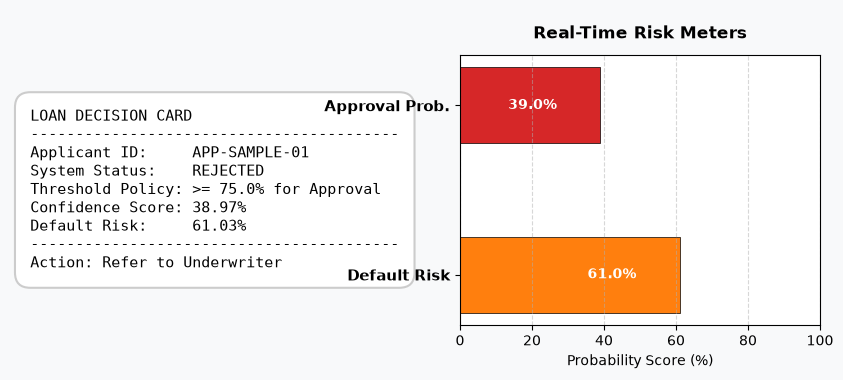

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Ensure DOCS_DIR exists
DOCS_DIR = PROJECT_ROOT / "docs" if 'PROJECT_ROOT' in globals() else Path("docs").resolve()
DOCS_DIR.mkdir(parents=True, exist_ok=True)

def render_loan_decision_card(pipeline, applicant_df, applicant_id: str = "APP-10492", save_filename: str = "product-v1-sketch.png"):
    # 1. Compute prediction and probabilities
    prob_approved = pipeline.predict_proba(applicant_df)[0, 1]
    prob_default = 1.0 - prob_approved
    decision = "APPROVED" if prob_approved >= 0.75 else "REJECTED"
    badge_color = "#2ca02c" if decision == "APPROVED" else "#d62728"
    
    # 2. Setup visualization canvas
    fig = plt.figure(figsize=(9, 4.5), facecolor="#f8f9fa")
    
    # Left Panel: Text Decision Card
    ax_card = fig.add_axes([0.05, 0.1, 0.45, 0.8])
    ax_card.axis('off')
    
    card_text = (
        f"LOAN DECISION CARD\n"
        f"-----------------------------------------\n"
        f"Applicant ID:     {applicant_id}\n"
        f"System Status:    {decision}\n"
        f"Threshold Policy: >= 75.0% for Approval\n"
        f"Confidence Score: {prob_approved * 100:.2f}%\n"
        f"Default Risk:     {prob_default * 100:.2f}%\n"
        f"-----------------------------------------\n"
        f"Action: {'Disburse Loan' if decision == 'APPROVED' else 'Refer to Underwriter'}"
    )
    
    ax_card.text(0.05, 0.5, card_text, fontsize=11, family='monospace', va='center',
                 bbox=dict(boxstyle='round,pad=1', facecolor='white', edgecolor='#cccccc', lw=1.5))
    
    # Right Panel: Risk Meters (Horizontal Gauges)
    ax_gauge = fig.add_axes([0.55, 0.2, 0.4, 0.6])
    categories = ['Default Risk', 'Approval Prob.']
    scores = [prob_default * 100, prob_approved * 100]
    bar_colors = ['#d62728' if prob_default > 25 else '#ff7f0e', badge_color]
    
    y_pos = np.arange(len(categories))
    bars = ax_gauge.barh(y_pos, scores, color=bar_colors, height=0.45, edgecolor='black', linewidth=0.5)
    
    ax_gauge.set_xlim(0, 100)
    ax_gauge.set_yticks(y_pos)
    ax_gauge.set_yticklabels(categories, fontsize=11, fontweight='bold')
    ax_gauge.set_xlabel('Probability Score (%)', fontsize=10)
    ax_gauge.set_title('Real-Time Risk Meters', fontsize=12, fontweight='bold', pad=12)
    ax_gauge.grid(axis='x', linestyle='--', alpha=0.5)
    
    # Add numerical labels inside bars
    for bar, score in zip(bars, scores):
        ax_gauge.text(bar.get_width() - 12 if score > 15 else bar.get_width() + 2, 
                      bar.get_y() + bar.get_height() / 2, 
                      f"{score:.1f}%", 
                      va='center', 
                      ha='left' if score <= 15 else 'right',
                      color='black' if score <= 15 else 'white', 
                      fontweight='bold', fontsize=10)
    
    # Save directly to docs/
    save_path = DOCS_DIR / save_filename
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Decision card saved to: {save_path}")
        
    plt.show()

# Run for a sample test applicant
sample_applicant = X_test.iloc[[0]]
render_loan_decision_card(ann_pipeline, sample_applicant, applicant_id="APP-SAMPLE-01", save_filename="product-v1-sketch.png")